# Instructions

- This homework assignment is worth **78** points. 
- Please strive for clarity and organization.
- **AI Usage**:
   - AI use is strictly **prohibited** for conceptual exercises.
   - For applied (Python) exercises, you may only use AI for **debugging**. Do not use AI to generate answers.
- **Due Date: October 30, 2026, by 11:59 PM.**

# Exercise 1 

You are working with a dataset containing sales information (shown below), but the data has several inconsistencies and formatting issues. Your task is to clean the data using Python, focusing on applying proper formatting, while following good coding practices (such as readable variable names, comments, consistent indentation, and use of functions). You will fix issues related to missing values, incorrect data types, string inconsistencies, and extra whitespaces.

| Customer ID | Name | Age | Gender | Purchase Amount | Purchase Date | Payment Method | Location |
| -------- | ------- | ------- | ------- | ------- | ------- | ------- | ------- |
| 1 | John Doe | 45 | Male | 2500.50 | 2023-01-15 | Creditcard | New York |
| 2 | jennifer Smith | 34 | female | 180.75 | 2022/05/12 | Bank Transfer | San Francisco |
| 3 | Ron Miller | NaN | Male | 500.0 | 2023/03/14 | PayPal | NewYork |
| 4 | Mary Johnson | 29 | Female | -120.00 | 2023-07-30 | Credit Card | Los Angeles |
| 5 | Tim Lewis | 41 | male | 75.0 | 2023-02-15 | cash | San Francisco |

### Exercise 1(a) (2 points)

Load `pandas` and `numpy`.

In [13]:
import pandas as pd
import numpy as np

### Exercise 1(b) (3 points)

Create a data frame called `df` with the below data dictionary.

```
data = {
    'Customer ID': [1, 2, 3, 4, 5],
    'Name': ['John Doe', 'jennifer Smith', 'Ron Miller', 'Mary Johnson', 'Tim Lewis'],
    'Age': [45, 34, np.nan, 29, 41],
    'Gender': ['Male', 'female', 'Male', 'Female', 'male'],
    'Purchase Amount': [2500.50, 180.75, 500.0, -120.00, 75.0],
    'Purchase Date': ['2023-01-15', '2022/05/12', '2023/03/14', '2023-07-30', '2023-02-15'],
    'Payment Method': ['Creditcard', 'Bank Transfer', 'PayPal', 'Credit Card', 'cash'],
    'Location': ['New York', 'San Francisco', 'NewYork', 'Los Angeles', 'San Francisco']
}
```

In [14]:
data = {
    'Customer ID': [1, 2, 3, 4, 5],
    'Name': ['John Doe', 'jennifer Smith', 'Ron Miller', 'Mary Johnson', 'Tim Lewis'],
    'Age': [45, 34, np.nan, 29, 41],
    'Gender': ['Male', 'female', 'Male', 'Female', 'male'],
    'Purchase Amount': [2500.50, 180.75, 500.0, -120.00, 75.0],
    'Purchase Date': ['2023-01-15', '2022/05/12', '2023/03/14', '2023-07-30', '2023-02-15'],
    'Payment Method': ['Creditcard', 'Bank Transfer', 'PayPal', 'Credit Card', 'cash'],
    'Location': ['New York', 'San Francisco', 'NewYork', 'Los Angeles', 'San Francisco']
}

df = pd.DataFrame(data)
df

,Customer ID,Name,Age,Gender,Purchase Amount,Purchase Date,Payment Method,Location
0,1,John Doe,45.0,Male,2500.50,2023-01-15,Creditcard,New York
1,2,jennifer Smith,34.0,female,180.75,2022/05/12,Bank Transfer,San Francisco
2,3,Ron Miller,NaN,Male,500.00,2023/03/14,PayPal,NewYork
3,4,Mary Johnson,29.0,Female,-120.00,2023-07-30,Credit Card,Los Angeles
4,5,Tim Lewis,41.0,male,75.00,2023-02-15,cash,San Francisco


### Exercise 1(c) (15 points)

Create a function that perfoms the below cleaning steps. Ensure that your code is well-formatted and uses good practices like function definitions, variable names, and comments.

- Standardize the `Gender` column:
    - Ensure that all values in the `Gender` column are either `Male` or `Female` (proper case).

- Handle missing values in the `Age` column:
    - Fill the missing values in the `Age` column with the average age of all customers.

- Fix formatting issues in the `Purchase Date` column:
    - Ensure all dates are in the format `YYYY-MM-DD`.

- Correct invalid values in the `Purchase Amount` column:
    - Replace any negative purchase amounts with their absolute values.

- Fix the `Payment Method` column:
    - Standardize the payment methods (`Creditcard`, `Credit Card` -> `Credit Card`).

- Remove extra spaces and correct inconsistent locations:
    - Remove any extra spaces in the `Location` column and ensure consistent formatting (e.g., `NewYork` -> `New York`).

- Write a function:
    - Create a function that performs all of the above cleaning steps in a single process and returns the cleaned DataFrame.

The expected output of the function should be:

| Customer ID | Name | Age | Gender | Purchase Amount | Purchase Date | Payment Method | Location |
| -------- | ------- | ------- | ------- | ------- | ------- | ------- | ------- |
| 1 | John Doe | 45 | Male | 2500.50 | 2023-01-15 | Credit Card | New York |
| 2 | jennifer Smith | 34 | Female | 180.75 | 2022-05-12 | Bank Transfer | San Francisco |
| 3 | Ron Miller | 37.25 | Male | 500.0 | 2023-03-14 | PayPal | New York |
| 4 | Mary Johnson | 29 | Female | 120.00 | 2023-07-30 | Credit Card | Los Angeles |
| 5 | Tim Lewis | 41 | Male | 75.0 | 2023-02-15 | Cash | San Francisco |

In [15]:

def clean_data(df):
    # Make a copy of the original data
    cleaned_df = df.copy()

    # Standardize gender
    cleaned_df["Gender"] = cleaned_df["Gender"].str.strip().str.title()

    # Fill missing ages with the average age
    cleaned_df["Age"] = cleaned_df["Age"].fillna(cleaned_df["Age"].mean())

    # Standardize purchase dates
    cleaned_df["Purchase Date"] = pd.to_datetime(
        cleaned_df["Purchase Date"], format="mixed"
    ).dt.strftime("%Y-%m-%d")

    # Change negative purchase amounts to positive
    cleaned_df["Purchase Amount"] = cleaned_df["Purchase Amount"].abs()

    # Standardize payment methods
    cleaned_df["Payment Method"] = cleaned_df["Payment Method"].str.strip()
    cleaned_df["Payment Method"] = cleaned_df["Payment Method"].replace({
        "Creditcard": "Credit Card",
        "cash": "Cash"
    })

    # Remove extra spaces and standardize locations
    cleaned_df["Location"] = cleaned_df["Location"].str.strip()
    cleaned_df["Location"] = cleaned_df["Location"].replace({
        "NewYork": "New York"
    })

    return cleaned_df


cleaned_df = clean_data(df)
cleaned_df


,Customer ID,Name,Age,Gender,Purchase Amount,Purchase Date,Payment Method,Location
0,1,John Doe,45.00,Male,2500.50,2023-01-15,Credit Card,New York
1,2,jennifer Smith,34.00,Female,180.75,2022-05-12,Bank Transfer,San Francisco
2,3,Ron Miller,37.25,Male,500.00,2023-03-14,PayPal,New York
3,4,Mary Johnson,29.00,Female,120.00,2023-07-30,Credit Card,Los Angeles
4,5,Tim Lewis,41.00,Male,75.00,2023-02-15,Cash,San Francisco


# Exercise 2 

In this exercise, we will explore the `shopping_trends.csv` data file. The Customer Shopping Preferences Dataset offers valuable insights into consumer behavior and purchasing patterns. Understanding customer preferences and trends is critical for businesses to tailor their products, marketing strategies, and overall customer experience. This dataset captures a wide range of customer attributes including age, gender, purchase history, preferred payment methods, frequency of purchases, and more. Analyzing this data can help businesses make informed decisions, optimize product offerings, and enhance customer satisfaction. The dataset stands as a valuable resource for businesses aiming to align their strategies with customer needs and preferences. A brief description of each of the columns in the data set is presented below.


- `Customer ID`: Unique identifier for each customer
- `Age`: Age of the customer
- `Gender`: Gender of the customer (Male/Female)
- `Item Purchased`: The item purchased by the customer
- `Category`: Category of the item purchased
- `Purchase Amount (USD)`: The amount of the purchase in USD
- `Location`: Location where the purchase was made
- `Size`: Size of the purchased item
- `Color`: Color of the purchased item
- `Season`: Season during which the purchase was made
- `Review Rating`: Rating given by the customer for the purchased item
- `Subscription Status`: Indicates if the customer has a subscription (Yes/No)
- `Shipping Type`: Type of shipping chosen by the customer
- `Discount Applied`: Indicates if a discount was applied to the purchase (Yes/No)
- `Promo Code Used`: Indicates if a promo code was used for the purchase (Yes/No)
- `Previous Purchases`: The total count of transactions concluded by the customer at the store, excluding the ongoing transaction
- `Payment Method`: Customer's most preferred payment method
- `Frequency of Purchases`: Frequency at which the customer makes purchases (e.g., Weekly, Fortnightly, Monthly)

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Exercise 2(b) (2 points)

Read the `shopping_trends.csv` data file and create a data frame called `df`.

In [17]:
import os
print(os.getcwd())

c:\Users\kginn\OneDrive\Desktop


In [18]:
df = pd.read_csv("shopping_trends.csv")
df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,Cash,2-Day Shipping,No,No,32,Venmo,Weekly
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,PayPal,Store Pickup,No,No,41,Bank Transfer,Bi-Weekly
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Credit Card,Standard,No,No,24,Venmo,Quarterly
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,PayPal,Express,No,No,24,Venmo,Weekly


### Exercise 2(c) (2 points)

Drop the `Customer ID` column.

In [19]:
df = df.drop(columns=["Customer ID"])
df.head()

,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


### Exercise 2(d) (4 points)

Visualize the distribution of `Age`. Describe the chart.

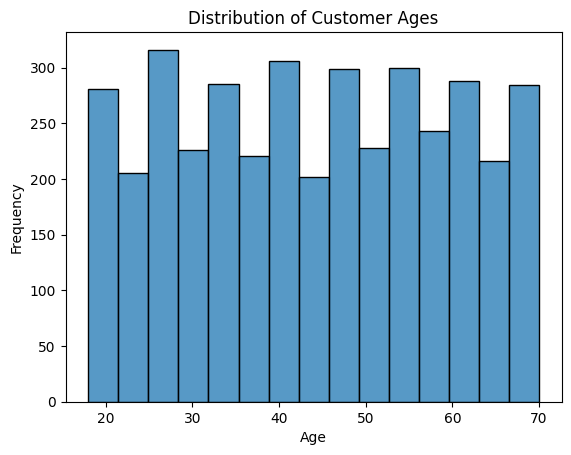

In [20]:
sns.histplot(data=df, x="Age", bins=15)
plt.title("Distribution of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

The histogram shows that customer ages range from about 18 to 70 years old. The ages are spread fairly evenly, with some small differences between age groups. There doesn't seem to be one age group that makes significantly more purchases than the others. Overall, the customer base includes a wide range of ages.

### Exercise 2(e) (2 points)

What is the most popular product category?

In [21]:
df["Category"].value_counts()

Category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64

Clothing is the most popular product category, with 1,737 purchases. Accessories comes in second with 1,240 purchases.

### Exercise 2(f) (3 points)

What is the average purchase amount for each product category?

In [22]:
df.groupby("Category")["Purchase Amount (USD)"].mean()

Category
Accessories    59.838710
Clothing       60.025331
Footwear       60.255426
Outerwear      57.172840
Name: Purchase Amount (USD), dtype: float64

The average purchase amount is $59.38 for Accessories, $60.03 for Clothing, $60.26 for Footwear, and $57.17 for Outerwear. Footwear has the highest average purchase amount, but the averages are fairly similar across all four categories.

### Exercise 2(g) (3 points)

What is the percentage of customers who have applied discounts on their purchases?

In [23]:
df["Discount Applied"].value_counts(normalize=True) * 100

Discount Applied
No     57.0
Yes    43.0
Name: proportion, dtype: float64

43% of customers applied a discount to their purchases, while 57% did not. This means slightly more customers made purchases without using a discount.

### Exercise 2(h) (6 points)

How does purchase amount vary across different payment methods? Create an appropriate chart that can help to answer this question.

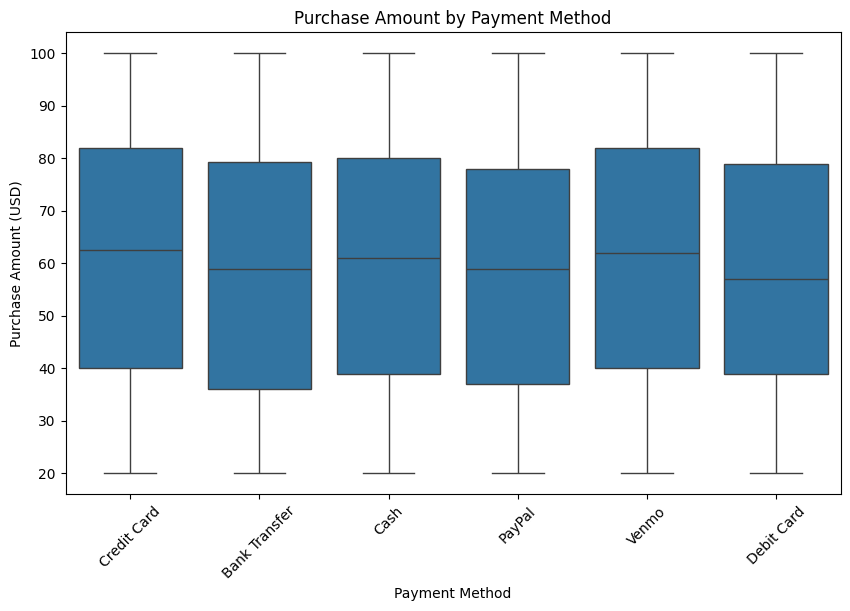

In [24]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="Payment Method", y="Purchase Amount (USD)")

plt.title("Purchase Amount by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Purchase Amount (USD)")
plt.xticks(rotation=45)
plt.show()

The boxplot shows that purchase amounts are pretty similar across the different payment methods. Credit Card and Venmo have slightly higher median purchase amounts, around $62, while Debit Card has the lowest, around $57. Overall, the ranges and distributions are similar, so payment method doesn't seem to make a big difference in how much customers spend.

### Exercise 2(i) (3 points)

What is the average number of previous purchases per customer?

In [25]:
df["Previous Purchases"].mean()

np.float64(25.35153846153846)

Customers have made an average of approximately 25 previous purchases.

### Exercise 2(j) (5 points)

Is there a relationship between `Purchase Amount (USD)` and `Review Rating`? Create the appropriate chart to answer this question.

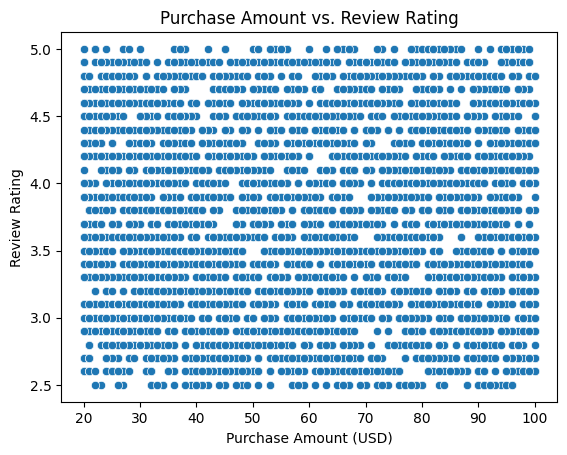

In [26]:

sns.scatterplot(data=df, x="Purchase Amount (USD)", y="Review Rating")

plt.title("Purchase Amount vs. Review Rating")
plt.xlabel("Purchase Amount (USD)")
plt.ylabel("Review Rating")
plt.show()


The scatterplot shows that there doesn't seem to be a strong relationship between purchase amount and review rating. Customers who spend more money don't necessarily give higher ratings. The ratings are spread across all purchase amounts, so spending more doesn't appear to affect how customers rate their purchases.

### Exercise 2(k) (3 points)

What percentage of customers use a subscription service?

In [27]:

df["Subscription Status"].value_counts(normalize=True) * 100


Subscription Status
No     73.0
Yes    27.0
Name: proportion, dtype: float64

27% of customers use a subscription service, while 73% do not. This means most customers are not subscribed.

### Exercise 2(l) (5 points)

What is the frequency of different shipping types selected by customers? Create the appropriate chart to answer this question.

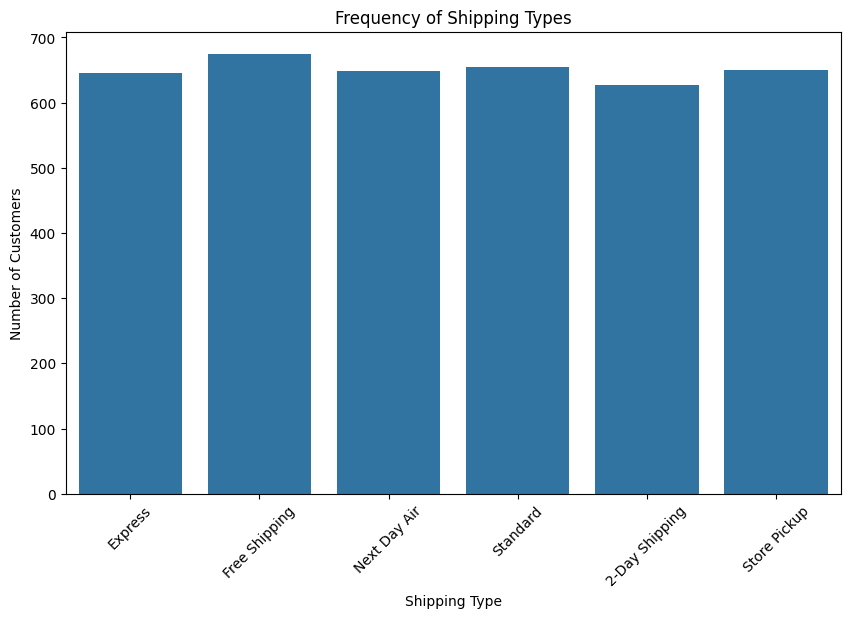

In [28]:

plt.figure(figsize=(10, 6))

sns.countplot(data=df, x="Shipping Type")

plt.title("Frequency of Shipping Types")
plt.xlabel("Shipping Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.show()


The chart shows that Free Shipping is the most popular shipping method, while 2-Day Shipping is the least popular. However, the differences between the shipping methods are pretty small. Overall, customers seem to use all six shipping options at fairly similar rates.

# Exercise 3

Formatters, linters, and type checkers each answer a different question about your code, and none of them requires running it.

### Exercise 3(a) (5 points)

For each of the following situations, state which tool (a **formatter** such as Black, a **linter** such as Ruff or Flake8, or a **type checker** such as mypy) is designed to detect or fix it, and explain why the other two tools would not.

1. The line `ax.plot(n, big_o[ i], label= line_names[i ])` has stray whitespace inside the brackets and around the keyword-argument equals sign.
2. A function calls `np.mean(values)`, but `numpy` was never imported.
3. A function annotated as `def load(path: str) -> str | None` is used as `load("model.yaml").upper()`.

*Your answer:*


**1. Formatter (Black):** I would use a formatter because the problem is with extra spaces and how the code is written. Black can automatically fix the formatting. A linter might flag some formatting issues, but it doesn't necessarily fix them. A type checker wouldn't help because there isn't a problem with the data types.

**2. Linter (Ruff or Flake8):** I would use a linter because `np` is being used without importing NumPy. A linter can catch undefined names. A formatter only changes how the code looks, and a type checker focuses on whether types are being used correctly rather than catching missing imports.

**3. Type checker (mypy):** I would use a type checker because the function can return either a string or `None`. Calling `.upper()` directly could cause an error if the result is `None`. A formatter wouldn't catch this because the formatting isn't the problem. A linter generally wouldn't catch it either because it's a type-related issue.

### Exercise 3(b) (4 points)

A teammate says: "I have format-on-save and linting turned on in my editor, so we do not need pre-commit hooks or continuous integration." Do you agree? Explain your answer in two to three sentences.

*Your answer:*


I don't agree because having formatting and linting turned on in one person's editor doesn't mean everyone on the team has the same settings. Pre-commit hooks help catch problems before code is committed, while continuous integration checks the code automatically when changes are pushed. Using all three helps keep the code consistent and reduces mistakes.

# Exercise 4

The function below runs and returns the correct answer, but it violates many of the conventions discussed in Chapter 6. It is supposed to compute the average of the values in a column that are strictly greater than a threshold, and to return `None` if no value qualifies.

```python
import sys, os
import pandas as pd
import numpy as np

def AvgPositive(DF,col,min = 0 ):
    sum=0
    count=0
    for i in range(len(DF)):
        if DF[col][i] > min: sum = sum + DF[col][i]; count = count + 1
    if count == 0: return None
    return sum/count
```

### Exercise 4(a) (5 points)

Rewrite the function so that it follows PEP8 and the naming conventions from Chapter 6. At a minimum, your version must:

- Import only the modules it needs, one per line.
- Use descriptive `snake_case` names for the function, its parameters, and its variables.
- Not shadow any Python builtins.
- Put each statement on its own line, use four-space indentation, and use the correct number of blank lines.
- Include a docstring.

You may keep the loop or replace it with a vectorized `pandas` expression.

In [29]:

import pandas as pd

def average_positive(dataframe, column_name, minimum=0):
    """Calculate the average of values greater than the minimum."""
    total = 0
    count = 0

    for value in dataframe[column_name]:
        if value > minimum:
            total += value
            count += 1

    if count == 0:
        return None

    return total / count


### Exercise 4(b) (4 points)

Add type annotations to your function from 4(a), using the modern syntax (e.g., `str | None`). Then use it to:

1. Compute the average of the strictly positive values of `Purchase Amount (USD)` in `shopping_trends.csv`.
2. Call the function on a small data frame where no value is above the threshold, and show that it returns `None`.

Finally, in a comment, state what error `mypy` would report for the call `average_positive("Purchase Amount (USD)", df)` (arguments in the wrong order), and whether Python itself would complain about the annotations before the function body runs.

In [30]:

def average_positive(
    dataframe: pd.DataFrame,
    column_name: str,
    minimum: float = 0
) -> float | None:
    """Return the average of values greater than the minimum."""
    total = 0
    count = 0

    for value in dataframe[column_name]:
        if value > minimum:
            total += value
            count += 1

    if count == 0:
        return None

    return total / count


# Average of positive purchase amounts
print(average_positive(df, "Purchase Amount (USD)"))


# Test when no values are above the threshold
test_df = pd.DataFrame({"Amount": [-10, -5, 0]})
print(average_positive(test_df, "Amount"))


# mypy would report incompatible argument types because
# the first argument should be a DataFrame, not a string,
# and the second argument should be a string, not a DataFrame.
# Python does not enforce type annotations at runtime.
# The incorrect call would fail when the function runs.


59.76435897435898
None
